<a href="https://colab.research.google.com/github/alexmordashov/image_processing/blob/main/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0%20%E2%84%96%2010/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%969_%D0%98%D1%81%D0%BF%D0%BE%D0%BB%D1%8C%D0%B7%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D0%B8_YOLOv12_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D0%B5_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87_%D0%B4%D0%B5%D1%82%D0%B5%D0%BA%D1%86%D0%B8%D0%B8_%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №9. Использование модели YOLOv26 для решение задач детекции и классификации**

## **Задание 1. Знакомство с новейшей версией модели YOLO**

- Ознакомьтесь с технической документацией по новейшей версии модели YOLOv26: https://docs.ultralytics.com/ru/models/yolo26/

- Рассмотрите пример обучения этой модели c использованием датасетов, созданных в Roboflow: https://colab.research.google.com/github/roboflow-ai/notebooks/blob/main/notebooks/train-yolo26-object-detection-on-custom-dataset.ipynb?ref=blog.roboflow.com

### **Ответьте на вопрос: Какие принципиальные отличия появились в модели YOLOv26 относительно предыдущих версий?**

**ВАШ ОТВЕТ**

Ключевые архитектурные изменения:
1. **Нативный дизайн без NMS.** Упрощение логики развёртывания и уменьшение задержки.
2. **Удаление Distribution Focal Loss.** Ускоряет вывод и значительно облегчает экспорт модели.
3. **Оптимизатор MuSGD.** Обеспечивает более быструю сходимость и более стабильный тренировочный процесс.

4. **Прогрессивная функция потерь и метки с учётом малых объектов.** Повышение точности обнаружения малых объектов.

*Примечание:* для каждого последующего задания, в конечном итоге, необходимо сформировать обученную модель и задеплоить её на сервисе **RoboFlow**



## **Задание 2. Найдите готовый датасет для детекции объектов и обучите на нем модель YOLOv26:**

- Для удобства работы с датасетом и деплоя модели используйте сервис [RoboFlow](https://roboflow.com/)

### 2.1. Проверка доступности GPU

In [3]:
!nvidia-smi

Mon Nov 16 19:31:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 2.2. Установка необходимых библиотек

In [4]:
!pip install -q -U ultralytics roboflow supervision inference pycuda Pillow

import warnings
warnings.filterwarnings('ignore')

### 2.3. Проверка установленных версий

In [5]:
import torch
import numpy as np
from ultralytics import YOLO

print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA version: {torch.version.cuda}")

PyTorch version: 2.14.1+cu130
NumPy version: 2.2.6
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


### 2.4. Настройка рабочих директорий

In [6]:
import os
from pathlib import Path

HOME = Path.cwd()
print(f"Рабочая директория: {HOME}")

WEIGHTS_DIR = HOME / "weights_1"
DATA_DIR = HOME / "data_1"
RESULTS_DIR = HOME / "results_1"

for directory in [WEIGHTS_DIR, DATA_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"Директория создана: {directory}")

Рабочая директория: /content
Директория создана: /content/weights_1
Директория создана: /content/data_1
Директория создана: /content/results_1


### 2.5. Авторизация в Roboflow

In [7]:
import roboflow

roboflow.login()
rf = roboflow.Roboflow()

You are already logged into Roboflow. To make a different login,run roboflow.login(force=True).


### 2.6. Загрузка датасета

In [8]:
WORKSPACE_NAME = "artems-workspace-9vapm"
PROJECT_NAME = "minecraft_capstone-gbn5g"

project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)

print("Доступные версии датасета:")
project.list_versions()

loading Roboflow workspace...
loading Roboflow project...
Доступные версии датасета:
[{'id': 'artems-workspace-9vapm/minecraft_capstone-gbn5g/1', 'name': '2026-11-15 12:29am', 'created': 1794692002.575, 'images': 397, 'splits': {'valid': 78, 'test': 40, 'train': 279}, 'generating': False, 'progress': 1, 'preprocessing': {}, 'augmentation': {}, 'exports': ['yolov9']}]


In [9]:
VERSION_NUMBER = 1

version = project.version(VERSION_NUMBER)
dataset = version.download("yolov8")

print(f"\nДатасет загружен в: {dataset.location}")
print(f"Путь к конфигурации: {dataset.location}/data.yaml")

Exporting format yolov8 in progress : 13.0%
Version export complete for yolov8 format

Датасет загружен в: /content/Minecraft_Capstone-1
Путь к конфигурации: /content/Minecraft_Capstone-1/data.yaml


### 2.7. Исследование структуры датасета

In [10]:
import yaml
from pathlib import Path

data_yaml_path = Path(dataset.location) / "data.yaml"

with open(data_yaml_path, 'r') as f:
    data_config = yaml.safe_load(f)

print("Конфигурация датасета:")
print("-" * 50)
print(f"Обучающая выборка: {data_config.get('train', 'не указана')}")
print(f"Валидационная выборка: {data_config.get('val', 'не указана')}")
print(f"Тестовая выборка: {data_config.get('test', 'не указана')}")
print(f"\nКлассы ({data_config.get('nc', 0)} шт.):")

for idx, class_name in enumerate(data_config.get('names', [])):
    print(f"  {idx}: {class_name}")

Конфигурация датасета:
--------------------------------------------------
Обучающая выборка: ../train/images
Валидационная выборка: ../valid/images
Тестовая выборка: ../test/images

Классы (6 шт.):
  0: cow
  1: creeper
  2: house
  3: pig
  4: villager
  5: white_sheep


### 2.8. Визуализация примеров из датасета

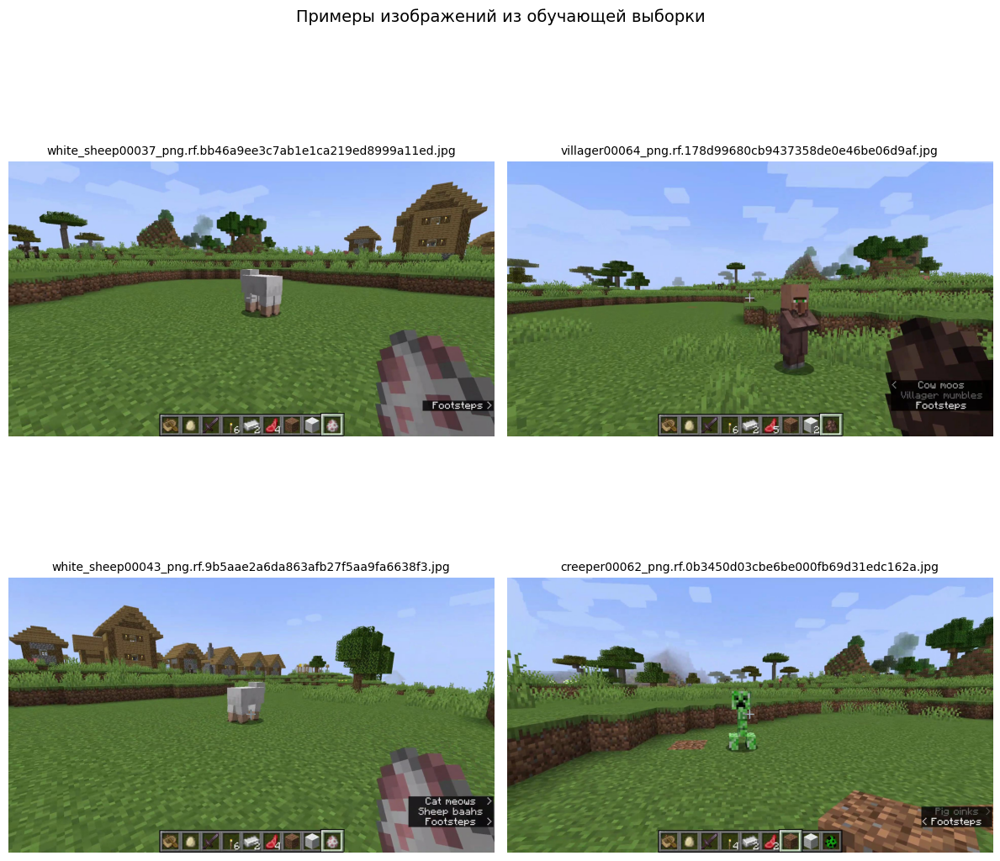

In [11]:
import random
from PIL import Image
import matplotlib.pyplot as plt

def visualize_dataset_samples(dataset_path, num_samples=4):
    train_images_path = Path(dataset_path) / "train" / "images"
    image_files = list(train_images_path.glob("*.jpg")) + list(train_images_path.glob("*.png"))

    if not image_files:
        print("Изображения не найдены!")
        return

    selected = random.sample(image_files, min(num_samples, len(image_files)))

    cols = 2
    rows = (num_samples + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(12, 6*rows))
    axes = axes.flatten() if num_samples > 1 else [axes]

    for ax, img_path in zip(axes, selected):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.set_title(img_path.name, fontsize=10)
        ax.axis('off')

    for ax in axes[len(selected):]:
        ax.axis('off')

    plt.suptitle('Примеры изображений из обучающей выборки', fontsize=14)
    plt.tight_layout()
    plt.show()

visualize_dataset_samples(dataset.location)

### 2.9. Настройка параметров обучения

In [12]:
import os

os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_SILENT"] = "true"
os.environ["CLEARML_DISABLE"] = "1"
os.environ["COMET_DISABLE"] = "1"

### 2.10. Конфигурация гиперпараметров

In [14]:
TRAINING_CONFIG = {
    'data': f"{dataset.location}/data.yaml",
    'epochs': 25,
    'batch': 16,
    'imgsz': 640,
    'device': 0,

    'optimizer': 'auto',
    'lr0': 0.01,
    'lrf': 0.01,
    'momentum': 0.937,
    'weight_decay': 0.0005,

    'hsv_h': 0.015,
    'hsv_s': 0.7,
    'hsv_v': 0.4,
    'degrees': 0.0,
    'translate': 0.1,
    'scale': 0.5,
    'fliplr': 0.5,
    'mosaic': 1.0,

    'close_mosaic': 15,
    'patience': 50,
    'save': True,
    'save_period': -1,
    'verbose': True,
    'project': str(RESULTS_DIR),
    'name': 'train_yolov26',
    'exist_ok': True,
}

print("Конфигурация обучения:")
print("-" * 50)
for key, value in TRAINING_CONFIG.items():
    print(f"{key:20}: {value}")

Конфигурация обучения:
--------------------------------------------------
data                : /content/Minecraft_Capstone-1/data.yaml
epochs              : 25
batch               : 16
imgsz               : 640
device              : 0
optimizer           : auto
lr0                 : 0.01
lrf                 : 0.01
momentum            : 0.937
weight_decay        : 0.0005
hsv_h               : 0.015
hsv_s               : 0.7
hsv_v               : 0.4
degrees             : 0.0
translate           : 0.1
scale               : 0.5
fliplr              : 0.5
mosaic              : 1.0
close_mosaic        : 15
patience            : 50
save                : True
save_period         : -1
verbose             : True
project             : /content/results_1
name                : train_yolov26
exist_ok            : True


### 2.11. Запуск обучения

In [16]:
from ultralytics import YOLO

model = YOLO('yolo26s.pt')

results = model.train(**TRAINING_CONFIG)

print("\n" + "=" * 50)
print("Обучение завершено!")
print(f"Результаты сохранены в: {results.save_dir}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Minecraft_Capstone-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_yolov26, nbs=64, nms=None, opset=None, opti

### 2.12. Загрузка и визуализация метрик

Файл не найден: results1.png
Файл не найден: confusion_matrix1.png
Файл не найден: confusion_matrix_normalized1.png


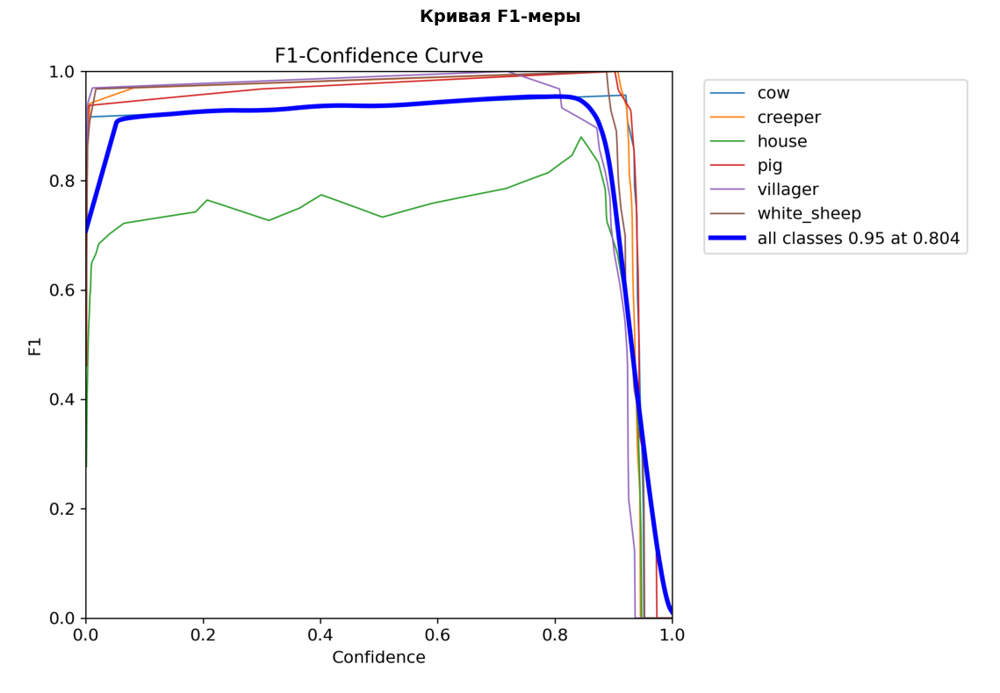

Файл не найден: BoxP_curve1.png
Файл не найден: BoxR_curve1.png
Файл не найден: BoxPR_curve1.png


In [17]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

def plot_training_results(results_dir):
    results_path = Path(results_dir)

    plots = [
        ('results1.png', 'Общие результаты обучения'),
        ('confusion_matrix1.png', 'Матрица ошибок'),
        ('confusion_matrix_normalized1.png', 'Нормализованная матрица ошибок'),
        ('BoxF1_curve.png', 'Кривая F1-меры'),
        ('BoxP_curve1.png', 'Кривая точности (Precision)'),
        ('BoxR_curve1.png', 'Кривая полноты (Recall)'),
        ('BoxPR_curve1.png', 'Кривая Precision-Recall'),
    ]

    for filename, title in plots:
        filepath = results_path / filename
        if filepath.exists():
            plt.figure(figsize=(12, 8))
            img = mpimg.imread(filepath)
            plt.imshow(img)
            plt.axis('off')
            plt.title(title, fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
        else:
            print(f"Файл не найден: {filename}")

plot_training_results(results.save_dir)

### 2.13. Анализ матрицы ошибок

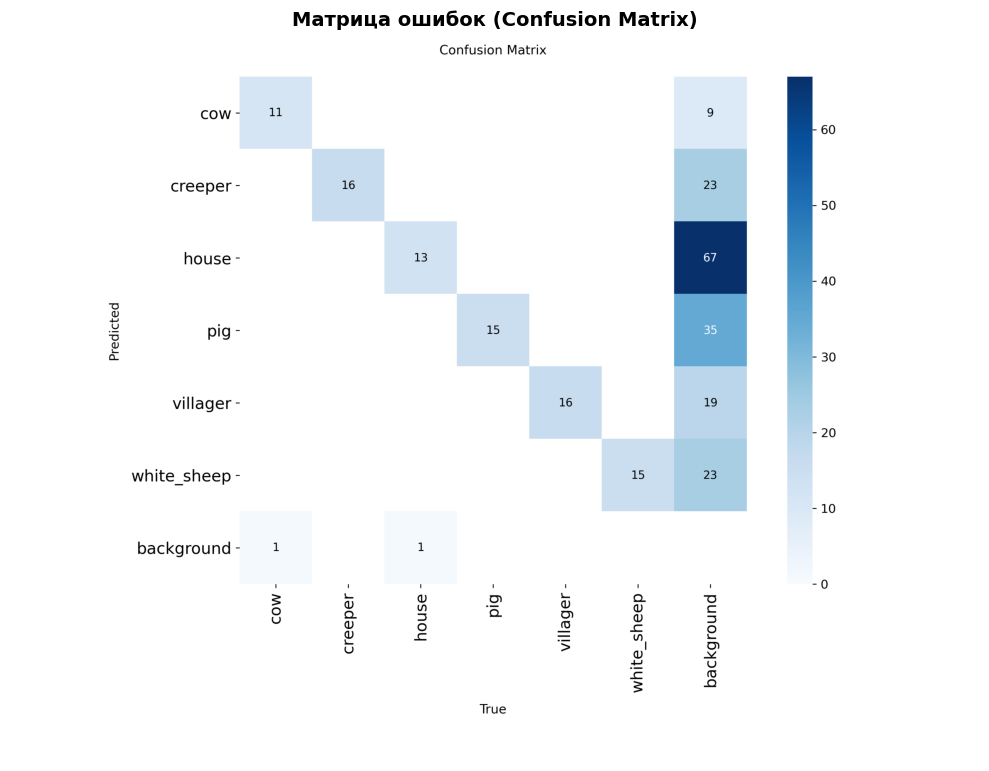

In [18]:
def analyze_confusion_matrix(results_dir):
    cm_path = Path(results_dir) / 'confusion_matrix.png'

    if cm_path.exists():
        plt.figure(figsize=(10, 10))
        img = mpimg.imread(cm_path)
        plt.imshow(img)
        plt.axis('off')
        plt.title('Матрица ошибок (Confusion Matrix)', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

analyze_confusion_matrix(results.save_dir)

### 2.14. Анализ кривых Precision-Recall

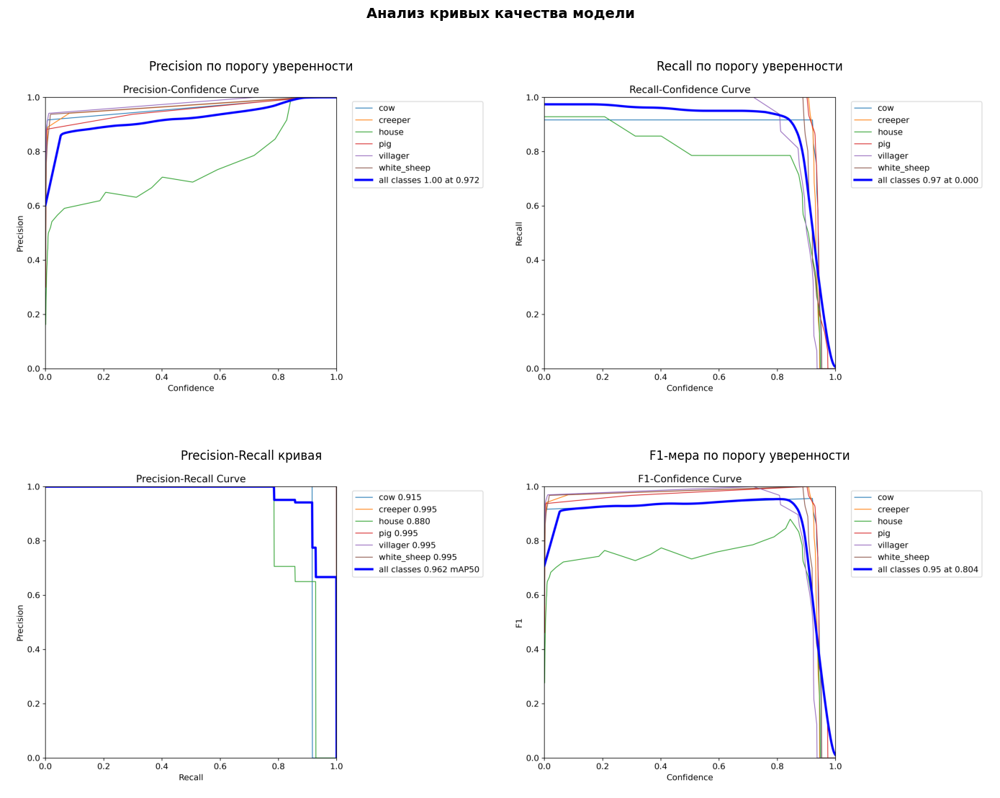

In [19]:
def analyze_pr_curves(results_dir):
    curves = ['BoxP_curve.png', 'BoxR_curve.png', 'BoxPR_curve.png', 'BoxF1_curve.png']
    titles = ['Precision по порогу уверенности',
              'Recall по порогу уверенности',
              'Precision-Recall кривая',
              'F1-мера по порогу уверенности']

    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes = axes.flatten()

    for ax, curve, title in zip(axes, curves, titles):
        curve_path = Path(results_dir) / curve
        if curve_path.exists():
            img = mpimg.imread(curve_path)
            ax.imshow(img)
            ax.set_title(title, fontsize=12)
        ax.axis('off')

    plt.suptitle('Анализ кривых качества модели', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

analyze_pr_curves(results.save_dir)

### 2.15. Запуск валидации

In [23]:
from ultralytics import YOLO

best_model_path = Path(results.save_dir) / 'weights' / 'best.pt'
model = YOLO(best_model_path)

VAL_CONFIG = {
    'data': f"{dataset.location}/data.yaml",
    'imgsz': 640,
    'batch': 32,
    'conf': 0.001,
    'iou': 0.7,
    'device': 0,
    'split': 'val',
    'save_json': True,
    'save_hybrid': True,
    'project': str(RESULTS_DIR),
    'name': 'val_yolov9',
    'exist_ok': True,
}

val_results = model.val(**VAL_CONFIG)

print("\n" + "=" * 50)
print("Результаты валидации:")
print("-" * 50)
print(f"mAP@50:     {val_results.box.map50:.4f}")
print(f"mAP@50:95:  {val_results.box.map:.4f}")
print(f"Precision:  {val_results.box.mp:.4f}")
print(f"Recall:     {val_results.box.mr:.4f}")

WARNING ⚠️ 'save_hybrid' is deprecated and will be removed in the future.
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3133.3±1221.3 MB/s, size: 212.1 KB)
val: Scanning /content/Minecraft_Capstone-1/valid/labels.cache... 78 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 78/78 23.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.2it/s 2.4s
                   all         78         88      0.973       0.94      0.962      0.879
                   cow         11         12      0.989      0.917      0.915      0.875
               creeper         16         16      0.993          1      0.995      0.932
                 house          8         14      0.874      0.786       0.88      0.737
                   pig         15         15     

### 2.16. Детальный анализ по классам

In [21]:
def print_class_metrics(val_results, class_names):
    print("\nМетрики по классам:")
    print("-" * 70)
    print(f"{'Класс':<20} {'Precision':>10} {'Recall':>10} {'mAP@50':>10} {'mAP@50:95':>10}")
    print("-" * 70)

    ap50 = val_results.box.ap50
    ap = val_results.box.ap

    for i, class_name in enumerate(class_names.values()):
        if i < len(ap50):
            print(f"{class_name:<20} {'-':>10} {'-':>10} {ap50[i]:>10.4f} {ap[i]:>10.4f}")

    print("-" * 70)
    print(f"{'Среднее':<20} {val_results.box.mp:>10.4f} {val_results.box.mr:>10.4f} {val_results.box.map50:>10.4f} {val_results.box.map:>10.4f}")

with open(f"{dataset.location}/data.yaml", 'r') as f:
    data_config = yaml.safe_load(f)

class_names = {i: name for i, name in enumerate(data_config['names'])}
print_class_metrics(val_results, class_names)


Метрики по классам:
----------------------------------------------------------------------
Класс                 Precision     Recall     mAP@50  mAP@50:95
----------------------------------------------------------------------
cow                           -          -     0.9150     0.8752
creeper                       -          -     0.9950     0.9320
house                         -          -     0.8799     0.7375
pig                           -          -     0.9950     0.9859
villager                      -          -     0.9950     0.8104
white_sheep                   -          -     0.9950     0.9334
----------------------------------------------------------------------
Среднее                  0.9734     0.9403     0.9625     0.8791


### 2.17. Визуализация результатов валидации

Файл не найден: results1.png
Файл не найден: confusion_matrix1.png
Файл не найден: confusion_matrix_normalized1.png


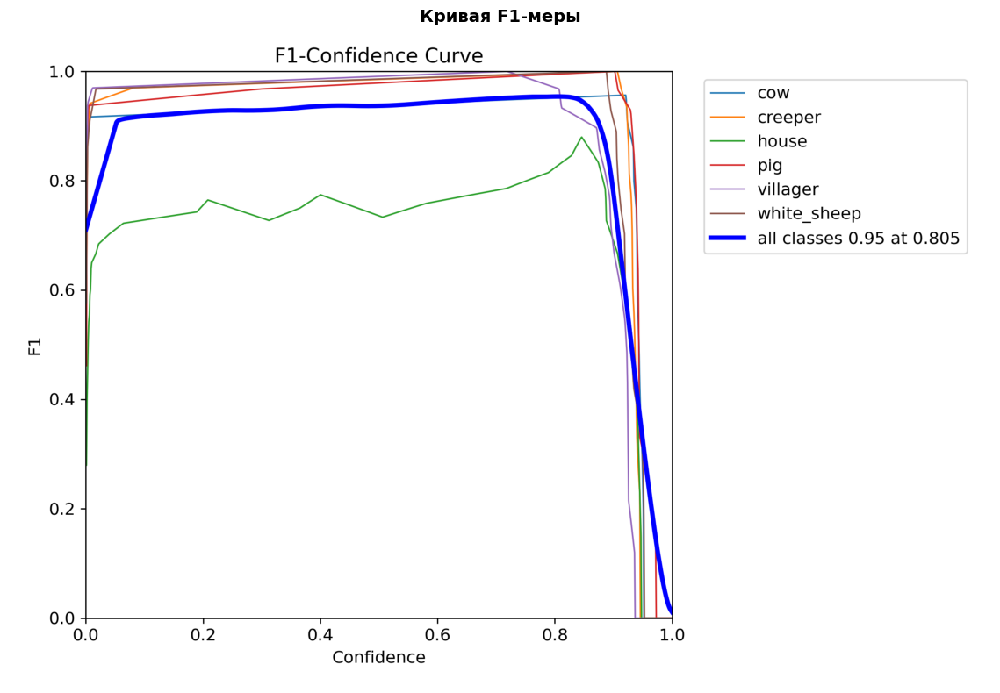

Файл не найден: BoxP_curve1.png
Файл не найден: BoxR_curve1.png
Файл не найден: BoxPR_curve1.png


In [22]:
plot_training_results(val_results.save_dir)

### 2.18. Детекция на тестовой выборке

In [24]:
from ultralytics import YOLO
from pathlib import Path

best_model_path = Path(results.save_dir) / 'weights' / 'best.pt'
model = YOLO(best_model_path)

test_images_path = Path(dataset.location) / 'test' / 'images'

PREDICT_CONFIG = {
    'source': str(test_images_path),
    'imgsz': 1280,
    'conf': 0.1,
    'iou': 0.45,
    'device': 0,
    'save': True,
    'save_txt': True,
    'save_conf': True,
    'project': str(RESULTS_DIR),
    'name': 'predict_yolov9',
    'exist_ok': True,
}

predict_results = model.predict(**PREDICT_CONFIG)

print(f"\nРезультаты сохранены в: {RESULTS_DIR / 'predict_yolov9'}")
print(f"Обработано изображений: {len(predict_results)}")


image 1/40 /content/Minecraft_Capstone-1/test/images/Screenshot-14-_png.rf.1d8a9e8dd585686ad6bde0bbf0e861bc.jpg: 736x1280 6 houses, 31.1ms
image 2/40 /content/Minecraft_Capstone-1/test/images/Screenshot-24-_png.rf.580ac3d0d9b02a476a8a80ad1cbe0e76.jpg: 736x1280 5 houses, 31.1ms
image 3/40 /content/Minecraft_Capstone-1/test/images/Screenshot-27-_png.rf.5b45da1b1cfd661421a5f8d272a3e626.jpg: 736x1280 4 houses, 31.1ms
image 4/40 /content/Minecraft_Capstone-1/test/images/Screenshot-8-_png.rf.23c5ba567e42380afa23cec9b98c5502.jpg: 736x1280 5 houses, 27.7ms
image 5/40 /content/Minecraft_Capstone-1/test/images/creeper00024_png.rf.dcf899e058907920d6142031f6ffd00f.jpg: 736x1280 1 creeper, 25.7ms
image 6/40 /content/Minecraft_Capstone-1/test/images/creeper00035_png.rf.df7e7e49b2cf6736c235553345759d16.jpg: 736x1280 1 creeper, 25.6ms
image 7/40 /content/Minecraft_Capstone-1/test/images/creeper00039_png.rf.bcf4a4cf4d16eadd19cafcdee8696945.jpg: 736x1280 1 creeper, 3 houses, 1 pig, 25.6ms
image 8/40 /c

### 2.19. Визуализация результатов инференса


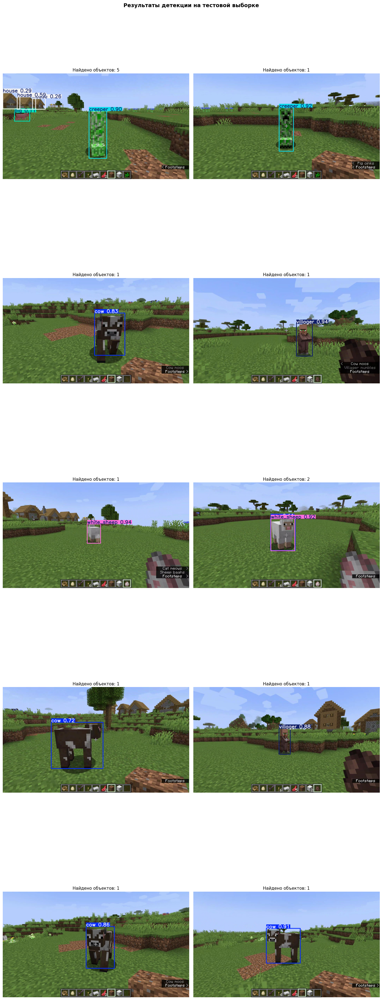

In [25]:
import matplotlib.pyplot as plt
import cv2
import random

def visualize_predictions(results, num_samples=4):
    selected = random.sample(results, min(num_samples, len(results)))

    cols = 2
    rows = (num_samples + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(14, 8*rows))
    axes = axes.flatten() if num_samples > 1 else [axes]

    for ax, result in zip(axes, selected):
        annotated = result.plot()
        annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

        ax.imshow(annotated_rgb)
        ax.set_title(f'Найдено объектов: {len(result.boxes)}', fontsize=11)
        ax.axis('off')

    for ax in axes[len(selected):]:
        ax.axis('off')

    plt.suptitle('Результаты детекции на тестовой выборке', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

visualize_predictions(predict_results, num_samples=10)

### 2.20. Детальный анализ отдельного изображения

Детальный анализ предсказания
Исходное изображение: /content/Minecraft_Capstone-1/test/images/Screenshot-14-_png.rf.1d8a9e8dd585686ad6bde0bbf0e861bc.jpg
Размер изображения: (1080, 1920)
Найдено объектов: 6
------------------------------------------------------------
№    Класс            Уверенность Координаты (x1,y1,x2,y2)
------------------------------------------------------------
1    house                89.68% (987, 355, 1325, 646)
2    house                89.21% (681, 356, 980, 638)
3    house                82.93% (142, 339, 677, 655)
4    house                59.13% (0, 333, 213, 626)
5    house                58.88% (1785, 445, 1920, 596)
6    house                37.95% (1714, 450, 1817, 587)


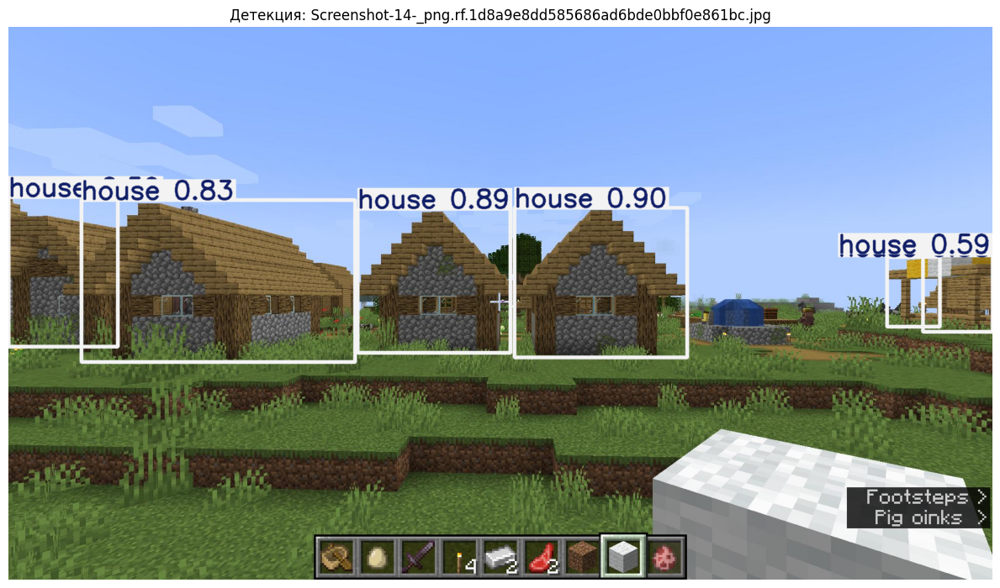

In [26]:
def analyze_single_prediction(result, model):
    print("Детальный анализ предсказания")
    print("=" * 60)
    print(f"Исходное изображение: {result.path}")
    print(f"Размер изображения: {result.orig_shape}")
    print(f"Найдено объектов: {len(result.boxes)}")
    print("-" * 60)

    if len(result.boxes) > 0:
        print(f"{'№':<4} {'Класс':<15} {'Уверенность':>12} {'Координаты (x1,y1,x2,y2)'}")
        print("-" * 60)

        for i, box in enumerate(result.boxes):
            class_id = int(box.cls)
            class_name = model.names[class_id]
            confidence = float(box.conf)
            coords = box.xyxy[0].tolist()
            coords_str = f"({coords[0]:.0f}, {coords[1]:.0f}, {coords[2]:.0f}, {coords[3]:.0f})"

            print(f"{i+1:<4} {class_name:<15} {confidence:>11.2%} {coords_str}")

    plt.figure(figsize=(12, 10))
    annotated = result.plot()
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    plt.imshow(annotated_rgb)
    plt.axis('off')
    plt.title(f'Детекция: {Path(result.path).name}', fontsize=12)
    plt.tight_layout()
    plt.show()

analyze_single_prediction(predict_results[0], model)

### 2.21. Подготовка к деплою

In [27]:
rf = roboflow.Roboflow()

project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)
version = project.version(VERSION_NUMBER)

print(f"Проект: {PROJECT_NAME}")
print(f"Версия: {VERSION_NUMBER}")
print(f"Путь к обученной модели: {results.save_dir}")

loading Roboflow workspace...
loading Roboflow project...
Проект: minecraft_capstone-gbn5g
Версия: 1
Путь к обученной модели: /content/results_1/train_yolov26


### 2.22. Загрузка модели в Roboflow

In [28]:
version.deploy(
    model_type="yolo26",
    model_path=str(results.save_dir)
)

print("\n" + "=" * 50)
print("Модель успешно загружена в Roboflow!")
print(f"Model ID: {PROJECT_NAME}/{VERSION_NUMBER}")

Inferred model size 'yolo26s' from the checkpoint architecture (model_type was 'yolo26').
View the status of your deployment at: https://app.roboflow.com/artems-workspace-9vapm/minecraft_capstone-gbn5g/1

Модель успешно загружена в Roboflow!
Model ID: minecraft_capstone-gbn5g/1


### 2.23. Использование развёрнутой модели

In [31]:
import getpass
import supervision as sv
from inference import get_model

print("Введите ваш Roboflow API ключ:")
ROBOFLOW_API_KEY = getpass.getpass()

model_id = "minecraft_capstone-gbn5g/1"
deployed_model = get_model(
    model_id=model_id,
    api_key=ROBOFLOW_API_KEY
)

print(f"Модель загружена: {model_id}")

Введите ваш Roboflow API ключ:
··········


Output()

Model requested device cuda, but the onnxruntime session runs only CPU-bound execution providers (CPUExecutionProvider) - falling back to cpu tensors for this model.


Модель загружена: minecraft_capstone-gbn5g/1


### 2.24. Инференс с использованием развёрнутой модели

In [32]:
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from roboflow import Roboflow

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)
version = project.version(VERSION_NUMBER)
models_list = version.models()
cloud_model = next(
    (m for m in models_list if "ships-4od7b-jdeam-1-yolo26s-t7" in str(vars(m))),
    models_list[0]
)

test_images = list(Path(dataset.location, 'test', 'images').glob('*.jpg'))
test_images += list(Path(dataset.location, 'test', 'images').glob('*.png'))

image_path = random.choice(test_images)

result = cloud_model.predict(str(image_path), confidence=10).json()

print(f"Изображение: {image_path.name}")
print(f"Найдено объектов: {len(result['predictions'])}")

for pred in result['predictions']:
    print(f"  - {pred['class']}: {pred['confidence']:.2%}")

loading Roboflow workspace...
loading Roboflow project...
Изображение: tree-extracted00022_png.rf.9ba7bcdc1e7b41d47647ef74b6b90856.jpg
Найдено объектов: 1
  - cow: 85.62%


### 2.25. Визуализация с помощью Supervision

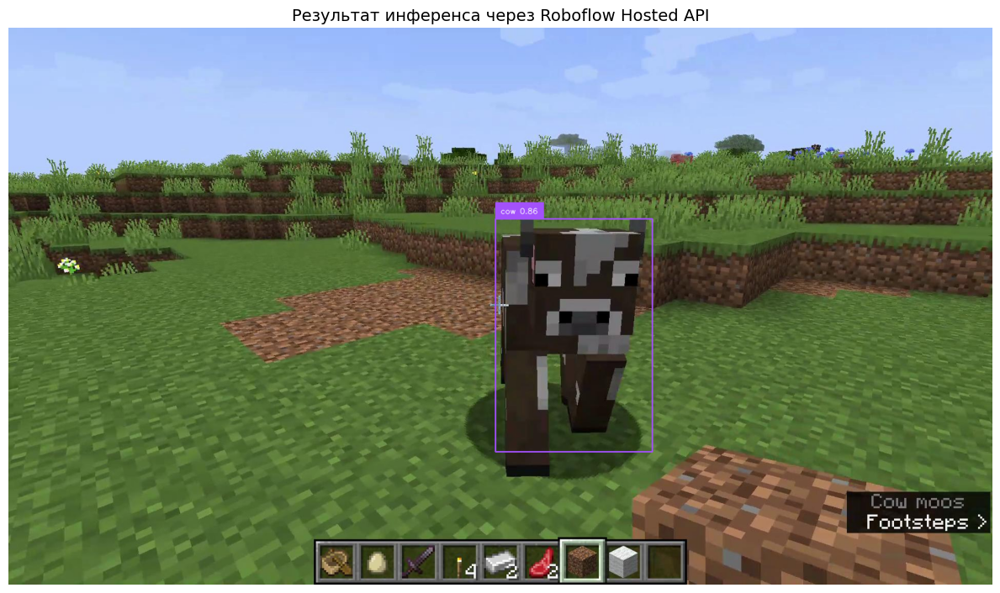

In [33]:
import supervision as sv
import cv2
import matplotlib.pyplot as plt

image = cv2.imread(str(image_path))

detections = sv.Detections.from_inference(result)

bounding_box_annotator = sv.BoxAnnotator(thickness=2)
label_annotator = sv.LabelAnnotator(text_scale=0.5, text_thickness=1)

annotated_image = bounding_box_annotator.annotate(
    scene=image.copy(),
    detections=detections
)

labels = [
    f"{pred['class']} {pred['confidence']:.2f}"
    for pred in result['predictions']
]

annotated_image = label_annotator.annotate(
    scene=annotated_image,
    detections=detections,
    labels=labels
)

plt.figure(figsize=(12, 10))
annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
plt.imshow(annotated_image_rgb)
plt.axis('off')
plt.title('Результат инференса через Roboflow Hosted API', fontsize=14)
plt.tight_layout()
plt.show()

## **Задание 3. Сформируйте свой датасет для детекции объектов и обучите на нем модель YOLOv26**



Требования к датасету:

- Количество изображений в датасете: минимум 90
- Количество классов: более 2х
- Обязательно должны присутствовать изображения, содержащие несколько классов одновременно


*Примечание: Формирование датасета включает в себя поиск изображений и ручное аннотирование объектов на изображениях.*

### 3.1. Проверка доступности GPU

In [2]:
!nvidia-smi

Mon Nov 16 22:23:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 3.2. Установка необходимых библиотек

In [3]:
!pip install -q -U ultralytics roboflow supervision inference pycuda Pillow

import warnings
warnings.filterwarnings('ignore')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing

### 3.3. Проверка установленных версий

In [2]:
import torch
import numpy as np
from ultralytics import YOLO

print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA version: {torch.version.cuda}")

PyTorch version: 2.14.1+cu130
NumPy version: 2.2.6
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


### 3.4. Настройка рабочих директорий

In [3]:
import os
from pathlib import Path

HOME = Path.cwd()
print(f"Рабочая директория: {HOME}")

WEIGHTS_DIR = HOME / "weights_2"
DATA_DIR = HOME / "data_2"
RESULTS_DIR = HOME / "results_2"

for directory in [WEIGHTS_DIR, DATA_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"Директория создана: {directory}")

Рабочая директория: /content
Директория создана: /content/weights_2
Директория создана: /content/data_2
Директория создана: /content/results_2


### 3.5. Авторизация в Roboflow

In [4]:
import roboflow

roboflow.login()
rf = roboflow.Roboflow()

You are already logged into Roboflow. To make a different login,run roboflow.login(force=True).


### 3.6. Загрузка датасета

In [5]:
WORKSPACE_NAME = "artems-workspace-9vapm"
PROJECT_NAME = "star-wars-mswpc"

project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)

print("Доступные версии датасета:")
project.list_versions()

loading Roboflow workspace...
loading Roboflow project...
Доступные версии датасета:
[{'id': 'artems-workspace-9vapm/star-wars-mswpc/3', 'name': '2026-11-17 1:35am', 'created': 1794868743.063, 'images': 97, 'splits': {'valid': 19, 'test': 10, 'train': 68}, 'generating': False, 'progress': 1, 'preprocessing': {'auto-orient': True, 'resize': {'format': 'Stretch to', 'width': '512', 'height': '512'}}, 'augmentation': {}, 'exports': ['yolov9']}]


In [6]:
VERSION_NUMBER = 3

version = project.version(VERSION_NUMBER)
dataset = version.download("yolov9")

print(f"\nДатасет загружен в: {dataset.location}")
print(f"Путь к конфигурации: {dataset.location}/data.yaml")


Датасет загружен в: /content/star-wars-3
Путь к конфигурации: /content/star-wars-3/data.yaml


### 3.7. Исследование структуры датасета

In [7]:
import yaml
from pathlib import Path

data_yaml_path = Path(dataset.location) / "data.yaml"

with open(data_yaml_path, 'r') as f:
    data_config = yaml.safe_load(f)

print("Конфигурация датасета:")
print("-" * 50)
print(f"Обучающая выборка: {data_config.get('train', 'не указана')}")
print(f"Валидационная выборка: {data_config.get('val', 'не указана')}")
print(f"Тестовая выборка: {data_config.get('test', 'не указана')}")
print(f"\nКлассы ({data_config.get('nc', 0)} шт.):")

for idx, class_name in enumerate(data_config.get('names', [])):
    print(f"  {idx}: {class_name}")

Конфигурация датасета:
--------------------------------------------------
Обучающая выборка: ../train/images
Валидационная выборка: ../valid/images
Тестовая выборка: ../test/images

Классы (9 шт.):
  0: dart vader
  1: droid
  2: human
  3: nothuman
  4: officer
  5: starship
  6: stormtrooper
  7: tank
  8: wookiee


### 3.8. Визуализация примеров из датасета

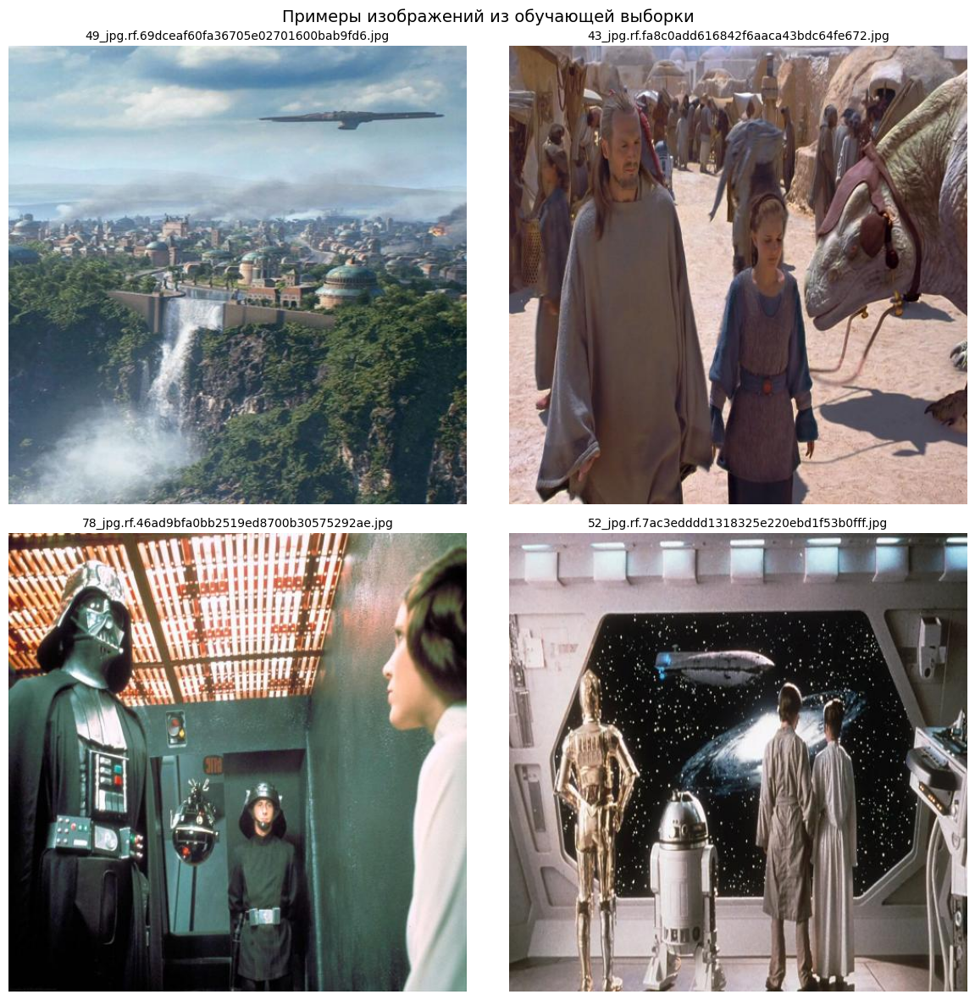

In [8]:
import random
from PIL import Image
import matplotlib.pyplot as plt

def visualize_dataset_samples(dataset_path, num_samples=4):
    train_images_path = Path(dataset_path) / "train" / "images"
    image_files = list(train_images_path.glob("*.jpg")) + list(train_images_path.glob("*.png"))

    if not image_files:
        print("Изображения не найдены!")
        return

    selected = random.sample(image_files, min(num_samples, len(image_files)))

    cols = 2
    rows = (num_samples + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(12, 6*rows))
    axes = axes.flatten() if num_samples > 1 else [axes]

    for ax, img_path in zip(axes, selected):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.set_title(img_path.name, fontsize=10)
        ax.axis('off')

    for ax in axes[len(selected):]:
        ax.axis('off')

    plt.suptitle('Примеры изображений из обучающей выборки', fontsize=14)
    plt.tight_layout()
    plt.show()

visualize_dataset_samples(dataset.location)

### 3.9. Настройка параметров обучения

In [9]:
import os

os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_SILENT"] = "true"
os.environ["CLEARML_DISABLE"] = "1"
os.environ["COMET_DISABLE"] = "1"

### 3.10. Конфигурация гиперпараметров

In [10]:
TRAINING_CONFIG = {
    'data': f"{dataset.location}/data.yaml",
    'epochs': 25,
    'batch': 16,
    'imgsz': 640,
    'device': 0,

    'optimizer': 'auto',
    'lr0': 0.01,
    'lrf': 0.01,
    'momentum': 0.937,
    'weight_decay': 0.0005,

    'hsv_h': 0.015,
    'hsv_s': 0.7,
    'hsv_v': 0.4,
    'degrees': 0.0,
    'translate': 0.1,
    'scale': 0.5,
    'fliplr': 0.5,
    'mosaic': 1.0,

    'close_mosaic': 15,
    'patience': 50,
    'save': True,
    'save_period': -1,
    'verbose': True,
    'project': str(RESULTS_DIR),
    'name': 'train_yolov26',
    'exist_ok': True,
}

print("Конфигурация обучения:")
print("-" * 50)
for key, value in TRAINING_CONFIG.items():
    print(f"{key:20}: {value}")

Конфигурация обучения:
--------------------------------------------------
data                : /content/star-wars-3/data.yaml
epochs              : 25
batch               : 16
imgsz               : 640
device              : 0
optimizer           : auto
lr0                 : 0.01
lrf                 : 0.01
momentum            : 0.937
weight_decay        : 0.0005
hsv_h               : 0.015
hsv_s               : 0.7
hsv_v               : 0.4
degrees             : 0.0
translate           : 0.1
scale               : 0.5
fliplr              : 0.5
mosaic              : 1.0
close_mosaic        : 15
patience            : 50
save                : True
save_period         : -1
verbose             : True
project             : /content/results_2
name                : train_yolov26
exist_ok            : True


### 3.11. Запуск обучения

In [11]:
from ultralytics import YOLO

model = YOLO('yolo26s.pt')

results = model.train(**TRAINING_CONFIG)

print("\n" + "=" * 50)
print("Обучение завершено!")
print(f"Результаты сохранены в: {results.save_dir}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/star-wars-3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_yolov26, nbs=64, nms=None, opset=None, optimize=Fals

### 3.12. Загрузка и визуализация метрик

Файл не найден: results1.png
Файл не найден: confusion_matrix1.png
Файл не найден: confusion_matrix_normalized1.png


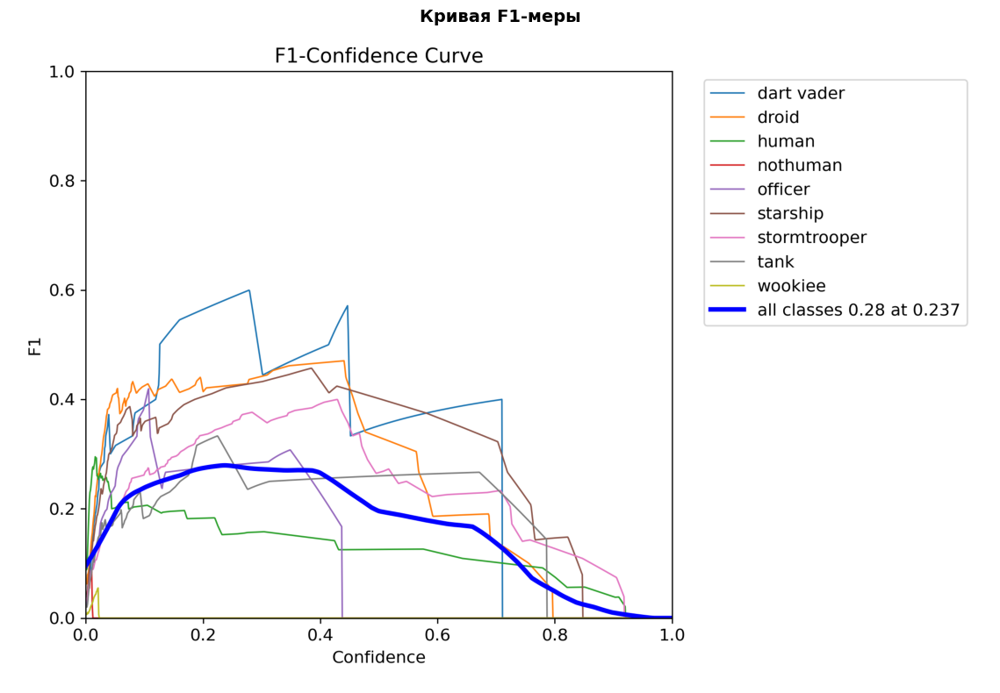

Файл не найден: BoxP_curve1.png
Файл не найден: BoxR_curve1.png
Файл не найден: BoxPR_curve1.png


In [12]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

def plot_training_results(results_dir):
    results_path = Path(results_dir)

    plots = [
        ('results1.png', 'Общие результаты обучения'),
        ('confusion_matrix1.png', 'Матрица ошибок'),
        ('confusion_matrix_normalized1.png', 'Нормализованная матрица ошибок'),
        ('BoxF1_curve.png', 'Кривая F1-меры'),
        ('BoxP_curve1.png', 'Кривая точности (Precision)'),
        ('BoxR_curve1.png', 'Кривая полноты (Recall)'),
        ('BoxPR_curve1.png', 'Кривая Precision-Recall'),
    ]

    for filename, title in plots:
        filepath = results_path / filename
        if filepath.exists():
            plt.figure(figsize=(12, 8))
            img = mpimg.imread(filepath)
            plt.imshow(img)
            plt.axis('off')
            plt.title(title, fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
        else:
            print(f"Файл не найден: {filename}")

plot_training_results(results.save_dir)

### 3.13. Анализ матрицы ошибок

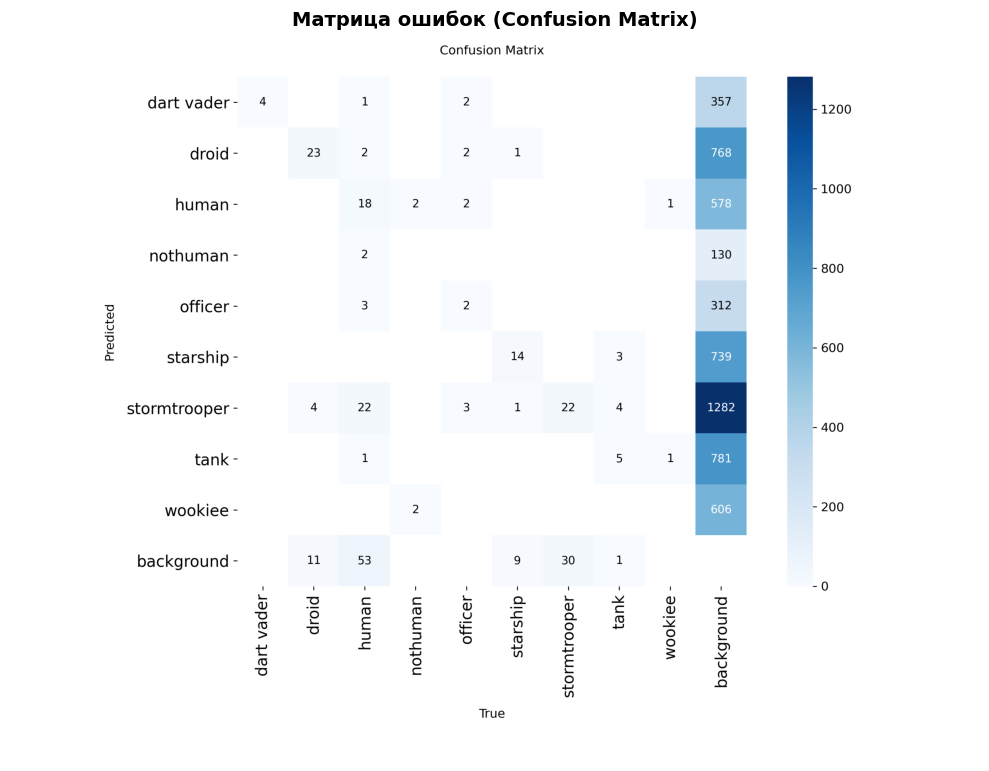

In [13]:
def analyze_confusion_matrix(results_dir):
    cm_path = Path(results_dir) / 'confusion_matrix.png'

    if cm_path.exists():
        plt.figure(figsize=(10, 10))
        img = mpimg.imread(cm_path)
        plt.imshow(img)
        plt.axis('off')
        plt.title('Матрица ошибок (Confusion Matrix)', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()

analyze_confusion_matrix(results.save_dir)

### 3.14. Анализ кривых Precision-Recall

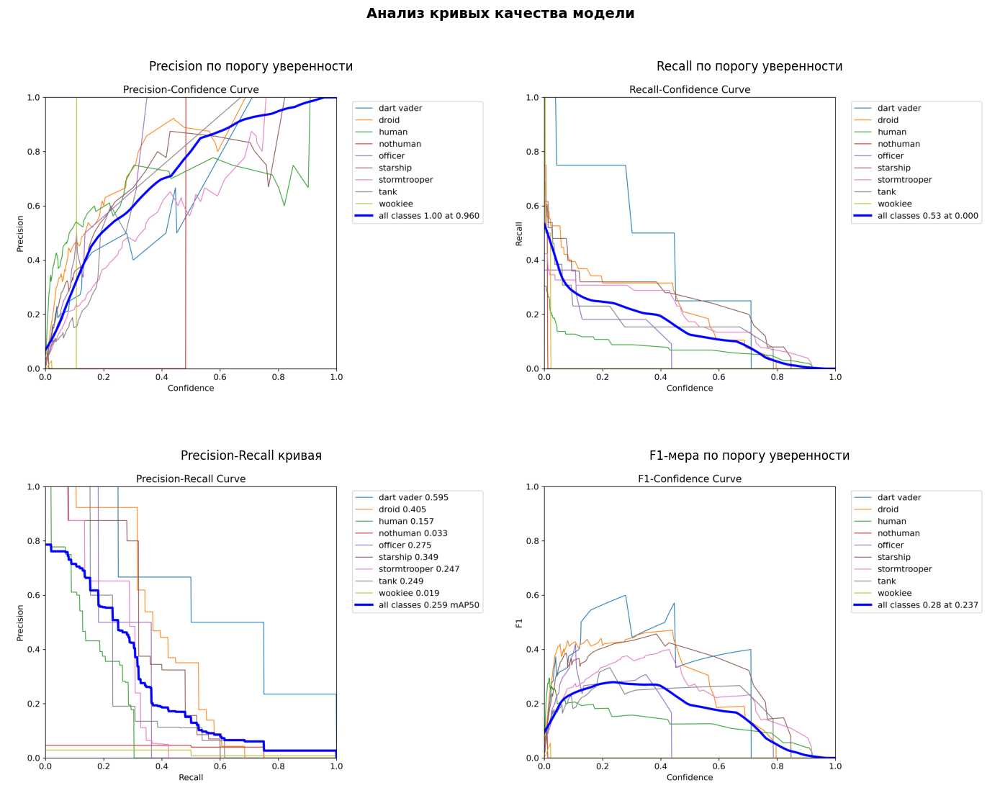

In [14]:
def analyze_pr_curves(results_dir):
    curves = ['BoxP_curve.png', 'BoxR_curve.png', 'BoxPR_curve.png', 'BoxF1_curve.png']
    titles = ['Precision по порогу уверенности',
              'Recall по порогу уверенности',
              'Precision-Recall кривая',
              'F1-мера по порогу уверенности']

    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes = axes.flatten()

    for ax, curve, title in zip(axes, curves, titles):
        curve_path = Path(results_dir) / curve
        if curve_path.exists():
            img = mpimg.imread(curve_path)
            ax.imshow(img)
            ax.set_title(title, fontsize=12)
        ax.axis('off')

    plt.suptitle('Анализ кривых качества модели', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

analyze_pr_curves(results.save_dir)

### 3.15. Запуск валидации

In [15]:
from ultralytics import YOLO

best_model_path = Path(results.save_dir) / 'weights' / 'best.pt'
model = YOLO(best_model_path)

VAL_CONFIG = {
    'data': f"{dataset.location}/data.yaml",
    'imgsz': 640,
    'batch': 32,
    'conf': 0.001,
    'iou': 0.7,
    'device': 0,
    'split': 'val',
    'save_json': True,
    'save_hybrid': True,
    'project': str(RESULTS_DIR),
    'name': 'val_yolov9',
    'exist_ok': True,
}

val_results = model.val(**VAL_CONFIG)

print("\n" + "=" * 50)
print("Результаты валидации:")
print("-" * 50)
print(f"mAP@50:     {val_results.box.map50:.4f}")
print(f"mAP@50:95:  {val_results.box.map:.4f}")
print(f"Precision:  {val_results.box.mp:.4f}")
print(f"Recall:     {val_results.box.mr:.4f}")

WARNING ⚠️ 'save_hybrid' is deprecated and will be removed in the future.
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,468,663 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1342.1±199.5 MB/s, size: 35.7 KB)
val: Scanning /content/star-wars-3/valid/labels.cache... 19 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 19/19 4.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.9it/s 0.5s
                   all         19        251      0.544      0.242      0.259      0.191
            dart vader          4          4      0.475       0.75      0.595      0.506
                 droid          6         38      0.648      0.316      0.405      0.214
                 human         11        102      0.577     0.0882      0.156        0.1
              nothuman          2          4          0      

### 3.16. Детальный анализ по классам

In [16]:
def print_class_metrics(val_results, class_names):
    print("\nМетрики по классам:")
    print("-" * 70)
    print(f"{'Класс':<20} {'Precision':>10} {'Recall':>10} {'mAP@50':>10} {'mAP@50:95':>10}")
    print("-" * 70)

    ap50 = val_results.box.ap50
    ap = val_results.box.ap

    for i, class_name in enumerate(class_names.values()):
        if i < len(ap50):
            print(f"{class_name:<20} {'-':>10} {'-':>10} {ap50[i]:>10.4f} {ap[i]:>10.4f}")

    print("-" * 70)
    print(f"{'Среднее':<20} {val_results.box.mp:>10.4f} {val_results.box.mr:>10.4f} {val_results.box.map50:>10.4f} {val_results.box.map:>10.4f}")

with open(f"{dataset.location}/data.yaml", 'r') as f:
    data_config = yaml.safe_load(f)

class_names = {i: name for i, name in enumerate(data_config['names'])}
print_class_metrics(val_results, class_names)


Метрики по классам:
----------------------------------------------------------------------
Класс                 Precision     Recall     mAP@50  mAP@50:95
----------------------------------------------------------------------
dart vader                    -          -     0.5955     0.5058
droid                         -          -     0.4050     0.2143
human                         -          -     0.1564     0.1003
nothuman                      -          -     0.0330     0.0310
officer                       -          -     0.2750     0.2231
starship                      -          -     0.3545     0.2502
stormtrooper                  -          -     0.2465     0.1505
tank                          -          -     0.2494     0.2297
wookiee                       -          -     0.0190     0.0099
----------------------------------------------------------------------
Среднее                  0.5438     0.2417     0.2594     0.1905


### 3.17. Визуализация результатов валидации

Файл не найден: results1.png
Файл не найден: confusion_matrix1.png
Файл не найден: confusion_matrix_normalized1.png


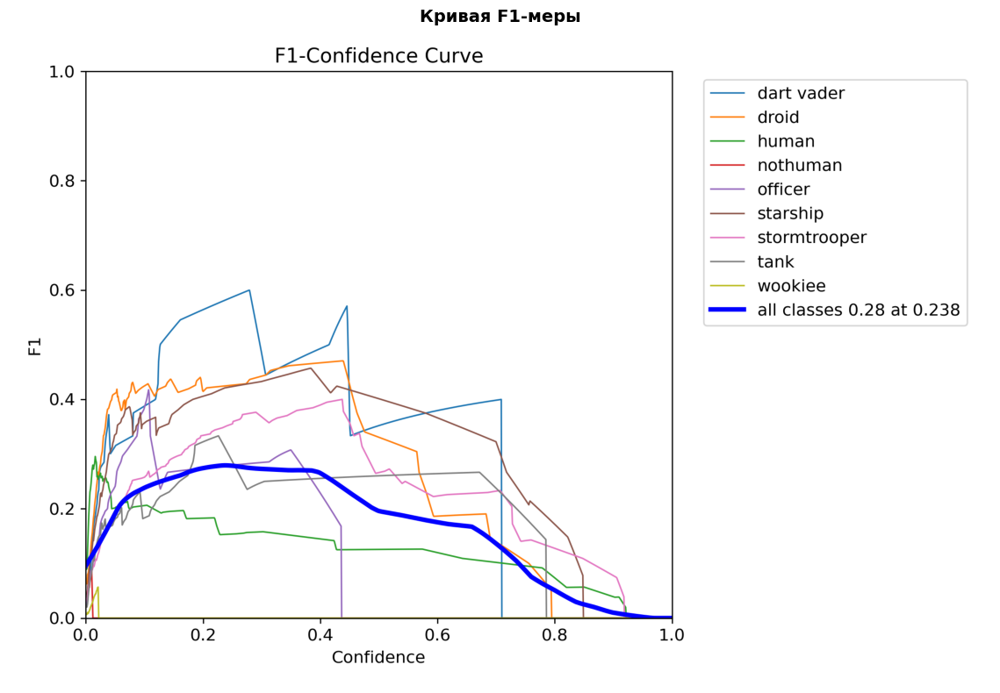

Файл не найден: BoxP_curve1.png
Файл не найден: BoxR_curve1.png
Файл не найден: BoxPR_curve1.png


In [17]:
plot_training_results(val_results.save_dir)

### 3.18. Детекция на тестовой выборке

In [18]:
from ultralytics import YOLO
from pathlib import Path

best_model_path = Path(results.save_dir) / 'weights' / 'best.pt'
model = YOLO(best_model_path)

test_images_path = Path(dataset.location) / 'test' / 'images'

PREDICT_CONFIG = {
    'source': str(test_images_path),
    'imgsz': 1280,
    'conf': 0.1,
    'iou': 0.45,
    'device': 0,
    'save': True,
    'save_txt': True,
    'save_conf': True,
    'project': str(RESULTS_DIR),
    'name': 'predict_yolov9',
    'exist_ok': True,
}

predict_results = model.predict(**PREDICT_CONFIG)

print(f"\nРезультаты сохранены в: {RESULTS_DIR / 'predict_yolov9'}")
print(f"Обработано изображений: {len(predict_results)}")


image 1/10 /content/star-wars-3/test/images/12_jpg.rf.3bcaba55c452b5b6aad69d1a2536bfb8.jpg: 1280x1280 (no detections), 51.0ms
image 2/10 /content/star-wars-3/test/images/18_jpg.rf.0aa32cc6039912c21968b9f047c0ade0.jpg: 1280x1280 1 human, 1 nothuman, 1 stormtrooper, 51.1ms
image 3/10 /content/star-wars-3/test/images/26_jpg.rf.1fe33d4af3f16ca00f329d4edd18880a.jpg: 1280x1280 3 humans, 6 stormtroopers, 1 wookiee, 33.7ms
image 4/10 /content/star-wars-3/test/images/28_jpg.rf.d6b3c24e2d433226fa44e6d06b8da44c.jpg: 1280x1280 2 nothumans, 6 starships, 4 stormtroopers, 33.6ms
image 5/10 /content/star-wars-3/test/images/54_jpg.rf.c0f6e536eed62de016f95c60bb55911e.jpg: 1280x1280 2 humans, 5 wookiees, 33.0ms
image 6/10 /content/star-wars-3/test/images/58_jpg.rf.513bf6a36a7febdfcfe78c001ddaec3c.jpg: 1280x1280 2 stormtroopers, 33.8ms
image 7/10 /content/star-wars-3/test/images/61_jpg.rf.1787740024499a0b1ae8fd5b075da47f.jpg: 1280x1280 2 droids, 6 humans, 5 nothumans, 8 stormtroopers, 3 tanks, 2 wookiees

### 3.19. Визуализация результатов инференса


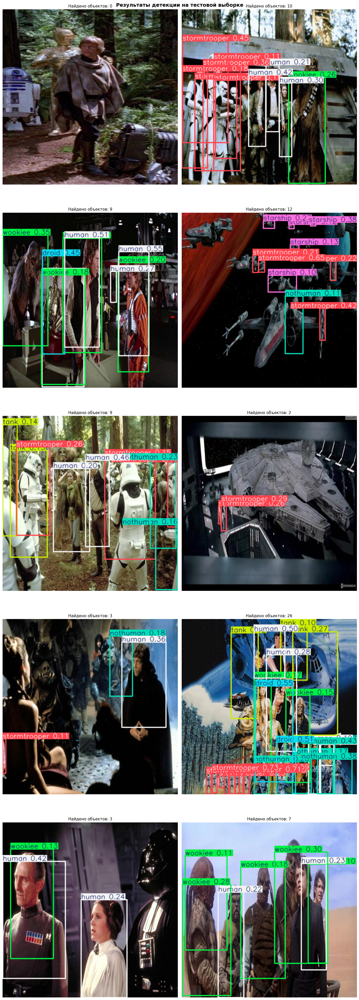

In [21]:
import matplotlib.pyplot as plt
import cv2
import random

def visualize_predictions(results, num_samples=4):
    selected = random.sample(results, min(num_samples, len(results)))

    cols = 2
    rows = (num_samples + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(14, 8*rows))
    axes = axes.flatten() if num_samples > 1 else [axes]

    for ax, result in zip(axes, selected):
        annotated = result.plot()
        annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

        ax.imshow(annotated_rgb)
        ax.set_title(f'Найдено объектов: {len(result.boxes)}', fontsize=11)
        ax.axis('off')

    for ax in axes[len(selected):]:
        ax.axis('off')

    plt.suptitle('Результаты детекции на тестовой выборке', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

visualize_predictions(predict_results, num_samples=10)

### 3.20. Детальный анализ отдельного изображения

Детальный анализ предсказания
Исходное изображение: /content/star-wars-3/test/images/26_jpg.rf.1fe33d4af3f16ca00f329d4edd18880a.jpg
Размер изображения: (512, 512)
Найдено объектов: 10
------------------------------------------------------------
№    Класс            Уверенность Координаты (x1,y1,x2,y2)
------------------------------------------------------------
1    stormtrooper         44.98% (3, 92, 135, 389)
2    human                42.44% (196, 192, 246, 400)
3    stormtrooper         35.91% (62, 164, 172, 471)
4    human                29.72% (285, 215, 321, 431)
5    wookiee              25.80% (313, 199, 419, 509)
6    human                21.47% (247, 163, 285, 358)
7    stormtrooper         18.34% (0, 182, 76, 464)
8    stormtrooper         11.19% (95, 146, 117, 205)
9    stormtrooper         10.64% (98, 207, 161, 436)
10   stormtrooper         10.25% (38, 203, 94, 471)


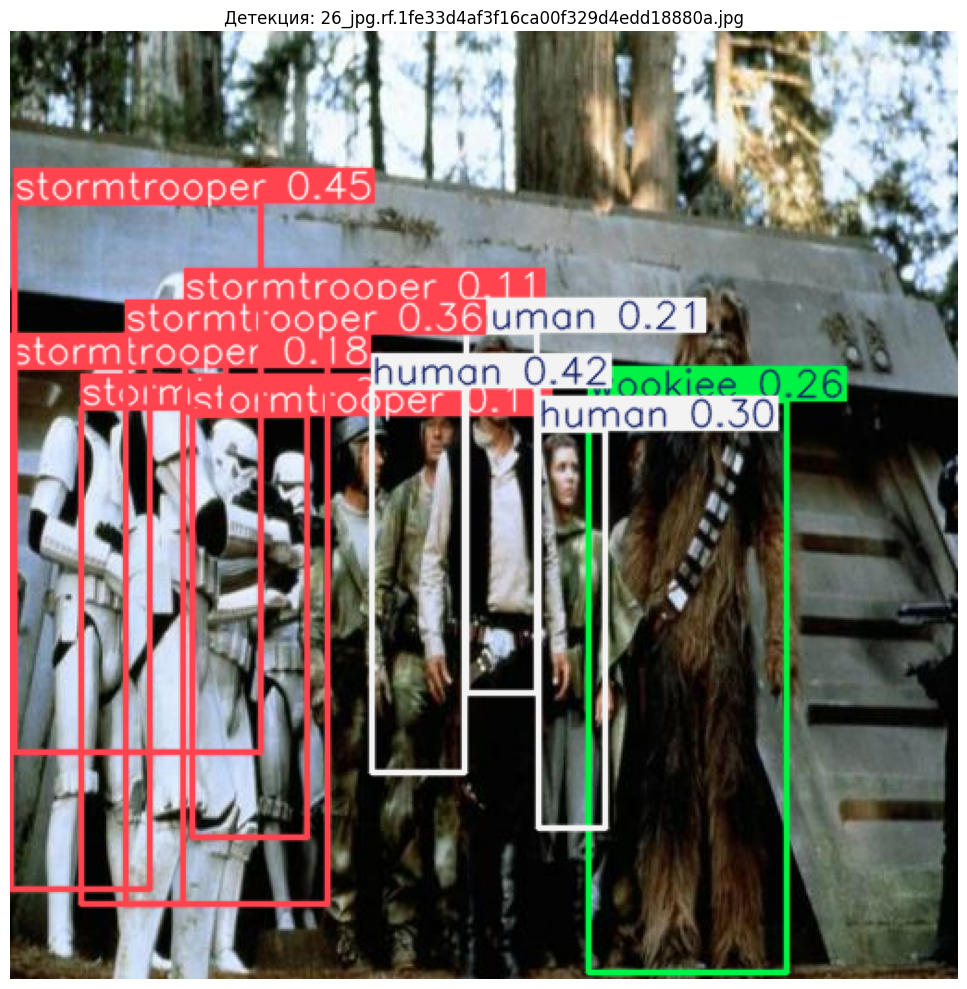

In [25]:
def analyze_single_prediction(result, model):
    print("Детальный анализ предсказания")
    print("=" * 60)
    print(f"Исходное изображение: {result.path}")
    print(f"Размер изображения: {result.orig_shape}")
    print(f"Найдено объектов: {len(result.boxes)}")
    print("-" * 60)

    if len(result.boxes) > 0:
        print(f"{'№':<4} {'Класс':<15} {'Уверенность':>12} {'Координаты (x1,y1,x2,y2)'}")
        print("-" * 60)

        for i, box in enumerate(result.boxes):
            class_id = int(box.cls)
            class_name = model.names[class_id]
            confidence = float(box.conf)
            coords = box.xyxy[0].tolist()
            coords_str = f"({coords[0]:.0f}, {coords[1]:.0f}, {coords[2]:.0f}, {coords[3]:.0f})"

            print(f"{i+1:<4} {class_name:<15} {confidence:>11.2%} {coords_str}")

    plt.figure(figsize=(12, 10))
    annotated = result.plot()
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    plt.imshow(annotated_rgb)
    plt.axis('off')
    plt.title(f'Детекция: {Path(result.path).name}', fontsize=12)
    plt.tight_layout()
    plt.show()

analyze_single_prediction(predict_results[2], model)

### 3.21. Подготовка к деплою

In [26]:
rf = roboflow.Roboflow()

project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)
version = project.version(VERSION_NUMBER)

print(f"Проект: {PROJECT_NAME}")
print(f"Версия: {VERSION_NUMBER}")
print(f"Путь к обученной модели: {results.save_dir}")

loading Roboflow workspace...
loading Roboflow project...
Проект: star-wars-mswpc
Версия: 3
Путь к обученной модели: /content/results_2/train_yolov26


### 3.22. Загрузка модели в Roboflow

In [27]:
version.deploy(
    model_type="yolo26",
    model_path=str(results.save_dir)
)

print("\n" + "=" * 50)
print("Модель успешно загружена в Roboflow!")
print(f"Model ID: {PROJECT_NAME}/{VERSION_NUMBER}")

Inferred model size 'yolo26s' from the checkpoint architecture (model_type was 'yolo26').
View the status of your deployment at: https://app.roboflow.com/artems-workspace-9vapm/star-wars-mswpc/3

Модель успешно загружена в Roboflow!
Model ID: star-wars-mswpc/3


### 3.23. Использование развёрнутой модели

In [30]:
import getpass
import supervision as sv
from inference import get_model

print("Введите ваш Roboflow API ключ:")
ROBOFLOW_API_KEY = getpass.getpass()

model_id = "star-wars-mswpc/3"
deployed_model = get_model(
    model_id=model_id,
    api_key=ROBOFLOW_API_KEY
)

print(f"Модель загружена: {model_id}")

Введите ваш Roboflow API ключ:
··········


Output()

Model requested device cuda, but the onnxruntime session runs only CPU-bound execution providers (CPUExecutionProvider) - falling back to cpu tensors for this model.


Модель загружена: star-wars-mswpc/3


### 3.24. Инференс с использованием развёрнутой модели

In [31]:
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from roboflow import Roboflow

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)
version = project.version(VERSION_NUMBER)
models_list = version.models()
cloud_model = next(
    (m for m in models_list if "ships-4od7b-jdeam-1-yolo26s-t7" in str(vars(m))),
    models_list[0]
)

test_images = list(Path(dataset.location, 'test', 'images').glob('*.jpg'))
test_images += list(Path(dataset.location, 'test', 'images').glob('*.png'))

image_path = random.choice(test_images)

result = cloud_model.predict(str(image_path), confidence=10).json()

print(f"Изображение: {image_path.name}")
print(f"Найдено объектов: {len(result['predictions'])}")

for pred in result['predictions']:
    print(f"  - {pred['class']}: {pred['confidence']:.2%}")

loading Roboflow workspace...
loading Roboflow project...
Изображение: 26_jpg.rf.1fe33d4af3f16ca00f329d4edd18880a.jpg
Найдено объектов: 10
  - stormtrooper: 89.15%
  - stormtrooper: 54.95%
  - human: 27.73%
  - stormtrooper: 27.66%
  - stormtrooper: 23.29%
  - human: 17.23%
  - human: 15.82%
  - human: 14.39%
  - human: 13.84%
  - stormtrooper: 10.95%


### 3.25. Визуализация с помощью Supervision

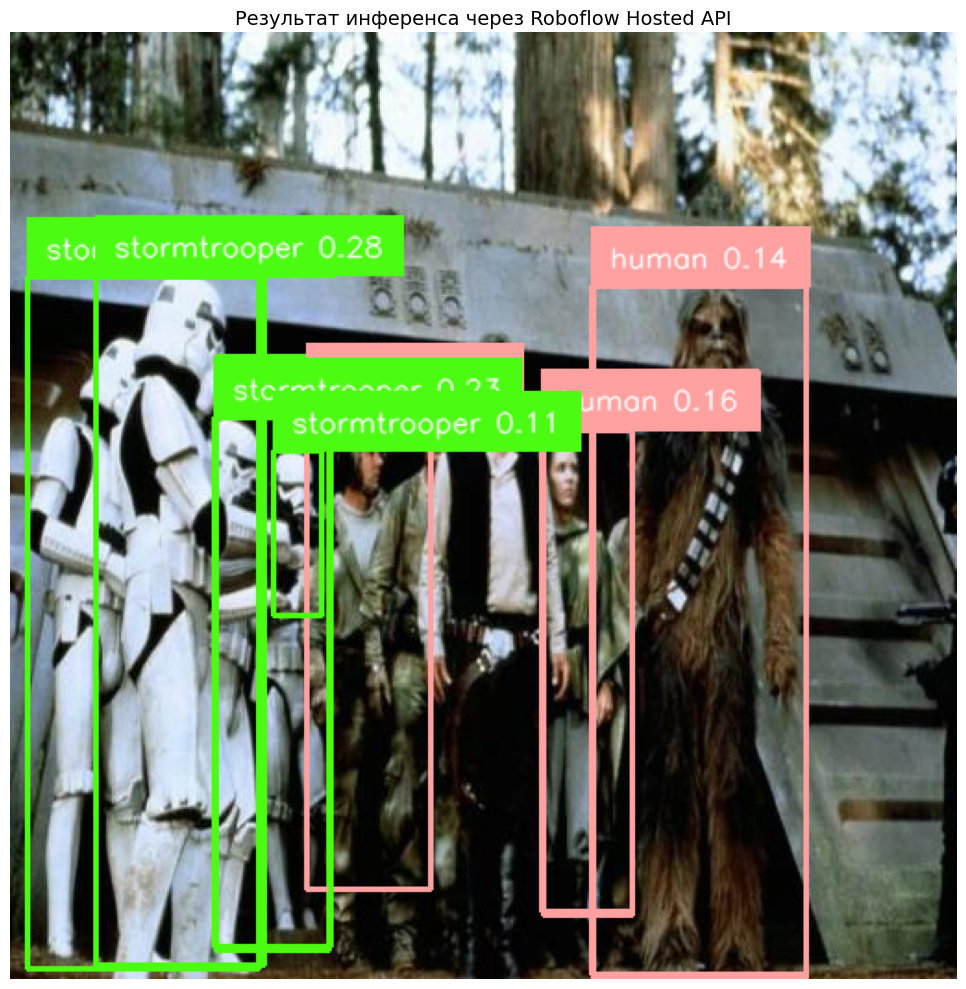

In [32]:
import supervision as sv
import cv2
import matplotlib.pyplot as plt

image = cv2.imread(str(image_path))

detections = sv.Detections.from_inference(result)

bounding_box_annotator = sv.BoxAnnotator(thickness=2)
label_annotator = sv.LabelAnnotator(text_scale=0.5, text_thickness=1)

annotated_image = bounding_box_annotator.annotate(
    scene=image.copy(),
    detections=detections
)

labels = [
    f"{pred['class']} {pred['confidence']:.2f}"
    for pred in result['predictions']
]

annotated_image = label_annotator.annotate(
    scene=annotated_image,
    detections=detections,
    labels=labels
)

plt.figure(figsize=(12, 10))
annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
plt.imshow(annotated_image_rgb)
plt.axis('off')
plt.title('Результат инференса через Roboflow Hosted API', fontsize=14)
plt.tight_layout()
plt.show()

## **Задание 4 (для магистрантов). Обучите модель YOLOv26 на датасете [RSD-GOD](https://github.com/Dr-Zhuang/geospatial-object-detection). Затем самостоятельно сформируйте тестовые данные (не менее 50 изображений с аннотациями) и оцените качество обученной модели:**



**Прямая ссылка на загрузку датасета: [загрузить](https://drive.google.com/open?id=1ttvSta0BRxW7tTV_st89vSb_obHVre34)**

**Ссылка на датасет в среде roboflow universe:** https://universe.roboflow.com/animals-sqrdn/rsd-god

 *Примечание: для поиска данных удобно использовать сервис Google Earth/Google Earth Engine*

In [ ]:
# Ваш код